In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
data = pd.read_csv("train.csv")
data['date'] = pd.to_datetime(data['date'])

df = data[(data['store']==1) & (data['item']==1)].copy()
df = df.sort_values('date')

df['lag_1'] = df['sales'].shift(1)
df['lag_7'] = df['sales'].shift(7)
df['lag_30'] = df['sales'].shift(30)

df['rolling_7'] = df['sales'].shift(1).rolling(7).mean()
df['rolling_30'] = df['sales'].shift(1).rolling(30).mean()

df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek

df = df.dropna()

In [3]:
features = ['lag_1','lag_7','lag_30','rolling_7','rolling_30','month','day_of_week']

split = int(len(df)*0.8)

train = df.iloc[:split]
valid = df.iloc[split:]

X_train = train[features]
y_train = train['sales']

X_valid = valid[features]
y_valid = valid['sales']

model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

model.fit(X_train,y_train)

predictions = model.predict(X_valid)

In [4]:
residuals = y_valid - predictions

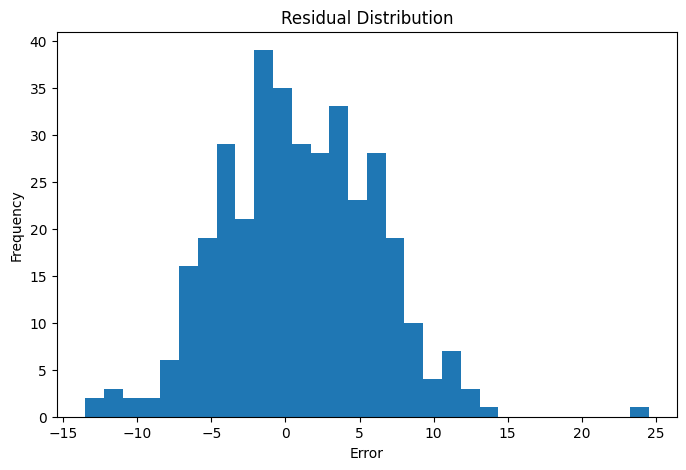

In [5]:
plt.figure(figsize=(8,5))
plt.hist(residuals, bins=30)
plt.title("Residual Distribution")
plt.xlabel("Error")
plt.ylabel("Frequency")
plt.show()

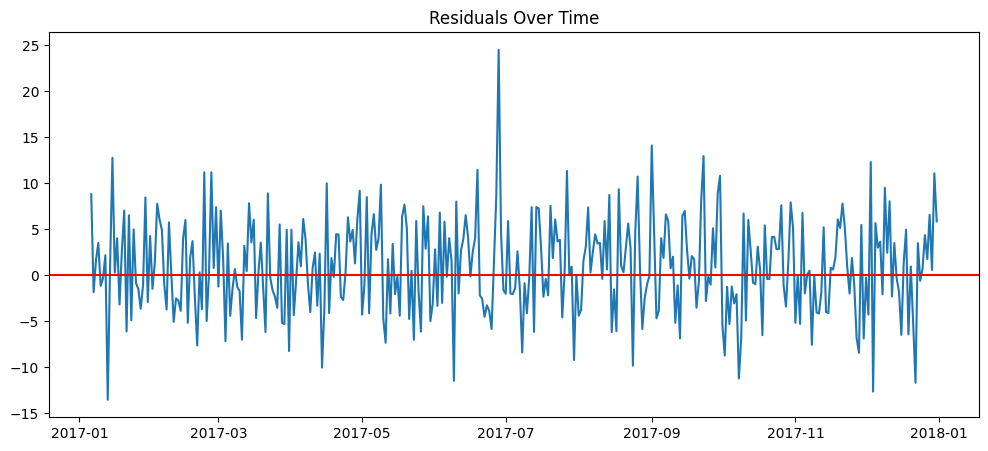

In [6]:
plt.figure(figsize=(12,5))
plt.plot(valid['date'], residuals)
plt.axhline(0,color='red')
plt.title("Residuals Over Time")
plt.show()

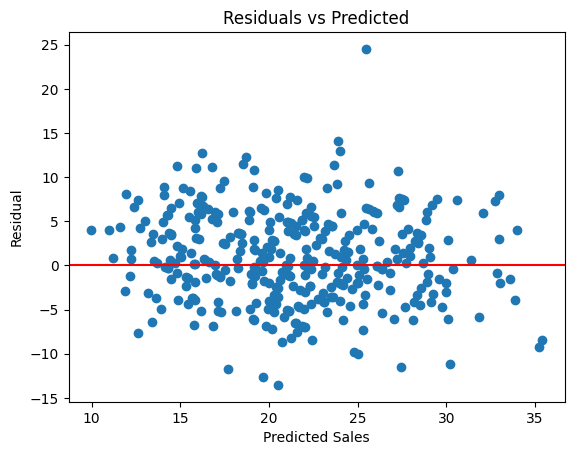

In [7]:
plt.scatter(predictions,residuals)
plt.axhline(0,color='red')
plt.title("Residuals vs Predicted")
plt.xlabel("Predicted Sales")
plt.ylabel("Residual")
plt.show()

In [8]:
mae = mean_absolute_error(y_valid,predictions)
rmse = np.sqrt(mean_squared_error(y_valid,predictions))

print("MAE:",mae)
print("RMSE:",rmse)
print("Mean residual:",residuals.mean())
print("Residual std:",residuals.std())

MAE: 4.187130451202393
RMSE: 5.256731712956441
Mean residual: 0.9237837606006198
Residual std: 5.1821276316471305
